#Import Libraries and Load Dataset

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("spam mail.csv")
df.head()

,Category,Masseges
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
df.shape

(5572, 2)

In [5]:
df.columns

Index(['Category', 'Masseges'], dtype='object')

In [6]:
df.isnull().sum()

,0
Category,0
Masseges,0


In [7]:
df.duplicated().sum()

np.int64(403)

EDA

<Axes: xlabel='Category', ylabel='count'>

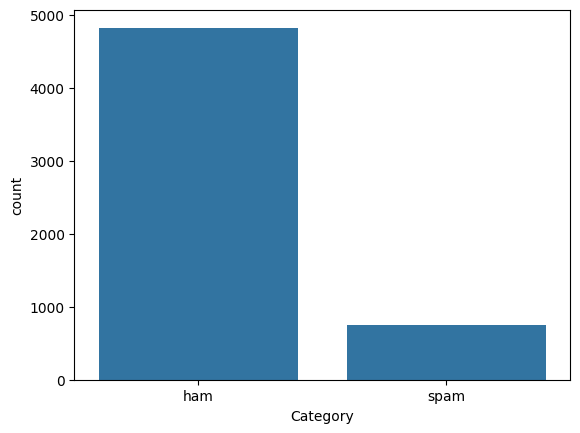

In [8]:
sns.countplot(x=df['Category'])

#Data Cleaning

In [9]:
df_copy = df.copy()
df_copy.drop_duplicates(inplace=True)

#Split The Data In Training and Testing part


In [10]:
from sklearn.model_selection import train_test_split
X = df_copy.drop('Category',axis=1)
y = df_copy['Category']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42,stratify=y)

#Data Preprocessing - Using NLP

In [11]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np

# Configure tokenizer
max_words = 10000
tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train['Masseges'])

# Convert text to sequences
train_sequence = tokenizer.texts_to_sequences(X_train['Masseges'])
test_sequence = tokenizer.texts_to_sequences(X_test['Masseges'])

# Pad sequences to ensure uniform input length
padded_train_sequence = pad_sequences(train_sequence, maxlen=50, padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequence, maxlen=50, padding='post', truncating='post')

# Encode target labels (ham = 0, spam = 1)
train_labels = np.array(y_train.map({'ham': 0, 'spam': 1}))
test_labels = np.array(y_test.map({'ham': 0, 'spam': 1}))
num_classes = len(np.unique(train_labels))

print(f"Vocabulary Size: {len(tokenizer.word_index)}")
print(f"Max Sentence Length: {padded_train_sequence.shape[1]}")
print(f"Padded Train Shape: {padded_train_sequence.shape}")
print(f"Padded Test Shape: {padded_test_sequence.shape}")

Vocabulary Size: 7013
Max Sentence Length: 50
Padded Train Shape: (3463, 50)
Padded Test Shape: (1706, 50)


In [12]:
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes = np.unique(train_labels),
    y=train_labels
)
class_weight_dict = dict(enumerate(class_weights))

In [13]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Plain Foundational Models

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU,LSTM,SimpleRNN,Embedding,Dense,Dropout
rnn_model = Sequential([
    Embedding(input_dim = max_words,output_dim=128,input_length=50),
    SimpleRNN(units =128,return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units = 60),
    Dropout(0.5),
    Dense(units=num_classes,activation='softmax')
])
rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [15]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 15s 86ms/step - accuracy: 0.5741 - loss: 0.8506 - val_accuracy: 0.1319 - val_loss: 0.7277
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.4921 - loss: 0.8485 - val_accuracy: 0.8734 - val_loss: 0.5842
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5039 - loss: 0.8180 - val_accuracy: 0.1266 - val_loss: 0.7574
Epoch 4/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5111 - loss: 0.7742 - val_accuracy: 0.8734 - val_loss: 0.6306
Epoch 5/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5077 - loss: 0.7538 - val_accuracy: 0.1307 - val_loss: 0.7029
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8734 - loss: 0.5842
RNN Loss: 0.5842359662055969
RNN Accuracy: 0.8733880519866943


#LSTM

In [16]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"LSTM Loss: {lstm_loss}")
print(f"LSTM Accuracy: {lstm_accuracy}")


Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - accuracy: 0.8634 - loss: 0.3504 - val_accuracy: 0.9086 - val_loss: 0.3173
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9186 - loss: 0.2780 - val_accuracy: 0.8740 - val_loss: 0.3426
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9264 - loss: 0.2178 - val_accuracy: 0.8781 - val_loss: 0.3595
Epoch 4/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9290 - loss: 0.1969 - val_accuracy: 0.8851 - val_loss: 0.3506
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9086 - loss: 0.3173
LSTM Loss: 0.31731414794921875
LSTM Accuracy: 0.9085580110549927


#Standard GRU

In [17]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])
gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"GRU Loss: {gru_loss}")
print(f"GRU Accuracy: {gru_accuracy}")

Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.4987 - loss: 0.7004 - val_accuracy: 0.1348 - val_loss: 0.7174
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.4632 - loss: 0.6977 - val_accuracy: 0.1319 - val_loss: 0.7237
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.5362 - loss: 0.6964 - val_accuracy: 0.1366 - val_loss: 0.7244
54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.1348 - loss: 0.7174
GRU Loss: 0.7173600196838379
GRU Accuracy: 0.13481828570365906


In [18]:
result_df = pd.DataFrame({
    'Model' : ['RNN', 'LSTM', 'GRU'],
    'Test Loss': [rnn_loss, lstm_loss, gru_loss],
    'Test Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Test Accuracy',ascending=False)
result_df

,Model,Test Loss,Test Accuracy
1,LSTM,0.317314,0.908558
0,RNN,0.584236,0.873388
2,GRU,0.717360,0.134818


#Advanced Bidirectional GRU

In [19]:
from tensorflow.keras.layers import Bidirectional

BiGRU = Sequential([
    Embedding(input_dim = max_words, output_dim = 300 , input_length = 50),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(64)),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [20]:
BiGRU.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
BiGRU.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 6s 23ms/step - accuracy: 0.8657 - loss: 0.2878 - val_accuracy: 0.9601 - val_loss: 0.1356
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.9902 - loss: 0.0485 - val_accuracy: 0.9848 - val_loss: 0.0555
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9986 - loss: 0.0055 - val_accuracy: 0.9824 - val_loss: 0.0680
Epoch 4/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.9991 - loss: 0.0026 - val_accuracy: 0.9812 - val_loss: 0.0830
Epoch 5/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 1.0000 - loss: 5.2351e-04 - val_accuracy: 0.9807 - val_loss: 0.0885


In [22]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequence, test_labels)
print(f"BiGRU Loss: {BiGRU_loss}")
print(f"BiGRU Accuracy: {BiGRU_accuracy}")


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9848 - loss: 0.0555
BiGRU Loss: 0.055534668266773224
BiGRU Accuracy: 0.9847596883773804


54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step


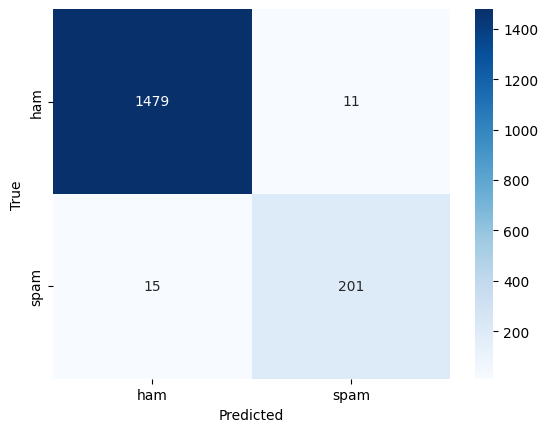

In [24]:
from sklearn.metrics import confusion_matrix
# Generate predictions first
BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence), axis=1)
label_names = ['ham', 'spam']
cm = confusion_matrix(test_labels, BiGRU_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_names, yticklabels=label_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

#Final Predictions

In [27]:
sample_texts = [
    "Hey! Just wanted to let you know about our new offers. Check them out today!",
    "Congratulations! You have won a $1,000,000 prize! Click here now to claim your reward!",
    "Hi there! You've got a new message waiting for you. Open it to see the details.",
    "Earn $5,000 every week from home with zero experience! Sign up now!",
    "Don't forget to check out our website for the latest updates and exciting news.",
    "URGENT: Your account will be suspended today! Verify your password immediately!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Text: Hey! Just wanted to let you know about our new offers. Check them out today!
Predicted Emotion: ham
Text: Congratulations! You have won a $1,000,000 prize! Click here now to claim your reward!
Predicted Emotion: spam
Text: Hi there! You've got a new message waiting for you. Open it to see the details.
Predicted Emotion: spam
Text: Earn $5,000 every week from home with zero experience! Sign up now!
Predicted Emotion: ham
Text: Don't forget to check out our website for the latest updates and exciting news.
Predicted Emotion: ham
Text: URGENT: Your account will be suspended today! Verify your password immediately!
Predicted Emotion: spam


In [28]:
import os
import pickle
model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)
#Save our BiGRU Model
BiGRU.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))
#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)